# E. All-model result comparison

한 번에 모음:
- torchvision Faster R-CNN (`tv_backbone_exps/frcnn_*`)
- Ultralytics YOLO (`runs/detect/*`, `tv_backbone_exps/yolo_scales/*`)

공통 지표: **AP50 / mAP50** (가능하면 mAP50-95도)

In [4]:
from pathlib import Path
import json
import re

import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent
FRCNN_ROOT = PROJECT / 'tv_backbone_exps'
YOLO_RUNS = [
    PROJECT / 'runs' / 'detect',
    FRCNN_ROOT / 'yolo_scales',
]
OUT = FRCNN_ROOT / 'compare_all'
OUT.mkdir(parents=True, exist_ok=True)

print('PROJECT', PROJECT)
print('FRCNN', FRCNN_ROOT, 'exists', FRCNN_ROOT.exists())
for r in YOLO_RUNS:
    print('YOLO', r, 'exists', r.exists())

PROJECT <PROJECT_ROOT>
FRCNN <PROJECT_ROOT>/tv_backbone_exps exists True
YOLO <PROJECT_ROOT>/runs/detect exists True
YOLO <PROJECT_ROOT>/tv_backbone_exps/yolo_scales exists False


In [5]:
def parse_frcnn_name(name: str):
    # frcnn_{backbone}__{pipe}
    m = re.match(r'^frcnn_(.+)__(.+)$', name)
    if not m:
        return None, None
    return m.group(1), m.group(2)


def load_frcnn_rows(root: Path):
    rows = []
    if not root.exists():
        return rows
    for d in sorted(root.glob('frcnn_*')):
        if not d.is_dir():
            continue
        backbone, pipe = parse_frcnn_name(d.name)
        hist_path = d / 'history.csv'
        metrics_path = d / 'metrics.json'
        best_ap, best_ep, last_ap, last_loss = None, None, None, None

        if hist_path.exists():
            hist = pd.read_csv(hist_path)
            if 'AP50' in hist.columns and len(hist):
                i = hist['AP50'].idxmax()
                best_ap = float(hist.loc[i, 'AP50'])
                best_ep = int(hist.loc[i, 'epoch']) if 'epoch' in hist.columns else None
                last_ap = float(hist.iloc[-1]['AP50'])
                if 'train_loss' in hist.columns:
                    last_loss = float(hist.iloc[-1]['train_loss'])
        elif metrics_path.exists():
            m = json.loads(metrics_path.read_text())
            best_ap = m.get('best_ap50')
            hist = m.get('history') or []
            if hist:
                best_ep = max(hist, key=lambda x: x.get('ap50', -1)).get('epoch')
                last_ap = hist[-1].get('ap50')
                last_loss = hist[-1].get('train_loss')

        # checkpoint meta fallback
        ckpt = d / 'best.pt'
        ckpt_ap, ckpt_ep = None, None
        if ckpt.exists():
            try:
                import torch
                obj = torch.load(ckpt, map_location='cpu', weights_only=False)
                if isinstance(obj, dict):
                    ckpt_ap = obj.get('AP50', obj.get('ap50'))
                    ckpt_ep = obj.get('epoch')
            except Exception as e:
                print('ckpt read skip', d.name, e)

        if best_ap is None and ckpt_ap is not None:
            best_ap, best_ep = ckpt_ap, ckpt_ep

        rows.append({
            'family': 'FRCNN',
            'exp': d.name,
            'model': backbone or d.name,
            'pipeline': pipe or '',
            'metric_AP50': best_ap,
            'metric_AP50_95': None,
            'best_epoch': best_ep,
            'last_AP50': last_ap,
            'last_train_loss': last_loss,
            'P': None,
            'R': None,
            'path': str(d),
        })
    return rows


def find_yolo_results_csv(run_dir: Path):
    # Ultralytics usually writes results.csv at run root
    cands = [run_dir / 'results.csv']
    cands += list(run_dir.glob('*/results.csv'))
    for c in cands:
        if c.exists():
            return c
    return None


def guess_yolo_meta(name: str):
    # yolo11n_original / yolo11_yolo11s__clahe_gamma / yolo11s_clahe_gamma
    model, pipe = name, ''
    for scale in ['yolo11x', 'yolo11l', 'yolo11m', 'yolo11s', 'yolo11n']:
        if scale in name:
            model = scale
            break
    for p in ['clahe_gamma', 'black_hat', 'clahe', 'original']:
        if p in name:
            pipe = p
            break
    return model, pipe


def load_yolo_rows(roots):
    rows = []
    seen = set()
    for root in roots:
        if not root.exists():
            continue
        # direct children that look like runs
        for d in sorted(root.iterdir()):
            if not d.is_dir():
                continue
            csv_path = find_yolo_results_csv(d)
            if csv_path is None:
                continue
            key = str(csv_path.resolve())
            if key in seen:
                continue
            seen.add(key)

            df = pd.read_csv(csv_path)
            df.columns = [c.strip() for c in df.columns]

            def col(*names):
                for n in names:
                    if n in df.columns:
                        return n
                # fuzzy
                for c in df.columns:
                    cl = c.lower()
                    for n in names:
                        if n.lower() in cl:
                            return c
                return None

            c50 = col('metrics/mAP50(B)', 'mAP50', 'metrics/mAP50')
            c95 = col('metrics/mAP50-95(B)', 'mAP50-95', 'metrics/mAP50-95')
            cP = col('metrics/precision(B)', 'precision')
            cR = col('metrics/recall(B)', 'recall')
            cEp = col('epoch')

            if c50 is None or df.empty:
                print('skip (no mAP50):', d)
                continue

            i = df[c50].idxmax()
            model, pipe = guess_yolo_meta(d.name)
            rows.append({
                'family': 'YOLO',
                'exp': d.name,
                'model': model,
                'pipeline': pipe,
                'metric_AP50': float(df.loc[i, c50]),
                'metric_AP50_95': float(df.loc[i, c95]) if c95 else None,
                'best_epoch': int(df.loc[i, cEp]) if cEp else None,
                'last_AP50': float(df.iloc[-1][c50]),
                'last_train_loss': None,
                'P': float(df.loc[i, cP]) if cP else None,
                'R': float(df.loc[i, cR]) if cR else None,
                'path': str(d),
            })
    return rows

In [1]:
rows = load_frcnn_rows(FRCNN_ROOT) + load_yolo_rows(YOLO_RUNS)
df = pd.DataFrame(rows)

if df.empty:
    raise SystemExit('결과 없음 — tv_backbone_exps / runs/detect 경로 확인')

df = df.sort_values(['metric_AP50'], ascending=False, na_position='last').reset_index(drop=True)
df['rank_AP50'] = range(1, len(df) + 1)

# display-friendly
show = df[[
    'rank_AP50', 'family', 'model', 'pipeline', 'exp',
    'metric_AP50', 'metric_AP50_95', 'P', 'R', 'best_epoch', 'path'
]].copy()
show['metric_AP50'] = show['metric_AP50'].map(lambda x: None if pd.isna(x) else round(float(x), 4))
show['metric_AP50_95'] = show['metric_AP50_95'].map(lambda x: None if pd.isna(x) else round(float(x), 4))

display(show)
csv_path = OUT / 'all_models_compare.csv'
show.to_csv(csv_path, index=False)
print('saved', csv_path)
print('\nBest overall:', show.iloc[0]['exp'], 'AP50=', show.iloc[0]['metric_AP50'])

NameError: name 'load_frcnn_rows' is not defined

In [4]:
# Family leaders
leaders = (
    df.dropna(subset=['metric_AP50'])
      .sort_values('metric_AP50', ascending=False)
      .groupby('family', as_index=False)
      .first()[['family', 'exp', 'model', 'pipeline', 'metric_AP50', 'metric_AP50_95']]
)
print('=== best per family ===')
display(leaders)

print('\n=== best per model ===')
by_model = (
    df.dropna(subset=['metric_AP50'])
      .sort_values('metric_AP50', ascending=False)
      .groupby('model', as_index=False)
      .first()[['model', 'family', 'pipeline', 'exp', 'metric_AP50']]
)
display(by_model.sort_values('metric_AP50', ascending=False))

=== best per family ===


,family,exp,model,pipeline,metric_AP50,metric_AP50_95
0,FRCNN,frcnn_resnet50_fpn__original,resnet50_fpn,original,0.295686,NaN
1,YOLO,yolo11n_clahe_gamma,yolo11n,clahe_gamma,0.345780,0.12645



=== best per model ===


,model,family,pipeline,exp,metric_AP50
3,yolo11n,YOLO,clahe_gamma,yolo11n_clahe_gamma,0.345780
4,yolo11s,YOLO,clahe_gamma,yolo11s__clahe_gamma,0.309730
1,resnet50_fpn,FRCNN,original,frcnn_resnet50_fpn__original,0.295686
2,resnet50_fpn_v2,FRCNN,clahe_gamma,frcnn_resnet50_fpn_v2__clahe_gamma,0.268508
0,mobilenet_v3_large_fpn,FRCNN,clahe_gamma,frcnn_mobilenet_v3_large_fpn__clahe_gamma,0.185888


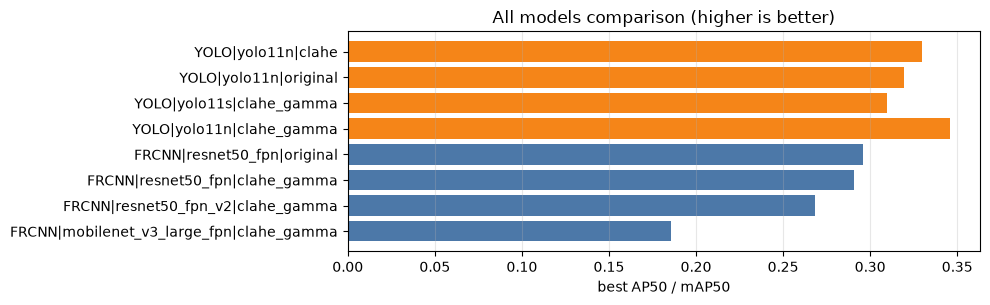

saved <PROJECT_ROOT>/tv_backbone_exps/compare_all/compare_ap50.png


In [5]:
# Bar: AP50 all experiments
plot_df = df.dropna(subset=['metric_AP50']).copy()
plot_df['label'] = plot_df.apply(
    lambda r: f"{r['family']}|{r['model']}|{r['pipeline'] or '-'}", axis=1
)

fig, ax = plt.subplots(figsize=(10, max(3, 0.35 * len(plot_df))))
colors = plot_df['family'].map({'FRCNN': '#4C78A8', 'YOLO': '#F58518'}).fillna('#999999')
ax.barh(plot_df['label'][::-1], plot_df['metric_AP50'][::-1], color=colors[::-1])
ax.set_xlabel('best AP50 / mAP50')
ax.set_title('All models comparison (higher is better)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
fig.savefig(OUT / 'compare_ap50.png', dpi=140)
plt.show()
print('saved', OUT / 'compare_ap50.png')

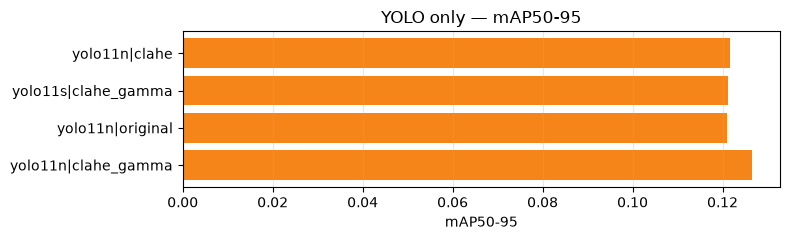

In [6]:
# Optional: YOLO mAP50-95 only (FRCNN notebook didn't log this)
yolo = df[(df['family'] == 'YOLO') & df['metric_AP50_95'].notna()].copy()
if len(yolo):
    yolo = yolo.sort_values('metric_AP50_95', ascending=False)
    fig, ax = plt.subplots(figsize=(8, max(2.5, 0.4 * len(yolo))))
    labels = yolo.apply(lambda r: f"{r['model']}|{r['pipeline'] or r['exp']}", axis=1)
    ax.barh(labels[::-1], yolo['metric_AP50_95'][::-1], color='#F58518')
    ax.set_xlabel('mAP50-95')
    ax.set_title('YOLO only — mAP50-95')
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    fig.savefig(OUT / 'compare_yolo_map50_95.png', dpi=140)
    plt.show()
else:
    print('YOLO mAP50-95 결과 없음 (runs/detect 아래 results.csv 확인)')

In [7]:
# Pivot: model x pipeline (AP50)
pivot = (
    df.dropna(subset=['metric_AP50'])
      .pivot_table(index='model', columns='pipeline', values='metric_AP50', aggfunc='max')
)
print('=== pivot AP50 (model x pipeline) ===')
display(pivot.round(4))
pivot.to_csv(OUT / 'pivot_ap50_model_x_pipeline.csv')
print('saved', OUT / 'pivot_ap50_model_x_pipeline.csv')

=== pivot AP50 (model x pipeline) ===


pipeline,clahe,clahe_gamma,original
model,,,
mobilenet_v3_large_fpn,NaN,0.1859,NaN
resnet50_fpn,NaN,0.2909,0.2957
resnet50_fpn_v2,NaN,0.2685,NaN
yolo11n,0.3296,0.3458,0.3193
yolo11s,NaN,0.3097,NaN


saved <PROJECT_ROOT>/tv_backbone_exps/compare_all/pivot_ap50_model_x_pipeline.csv


## 읽는 법

- FRCNN의 `AP50`과 YOLO의 `mAP50`은 **비슷한 축**이지만 전처리/디코더/score threshold가 달라 **절대값 1:1은 조심**.
- 같은 family 안 순위는 신뢰도 높음.
- 저장 위치: `ARCADE/tv_backbone_exps/compare_all/`